<a href="https://colab.research.google.com/github/NSPFD/Thai-quantum-computing-2026/blob/main/Variational_Quantum_Eigensolver_VQE_H2_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Variational Quantum Eigensolver (VQE) for the Hydrogen Molecule

Estimate the ground-state energy of **H₂** (STO-3G basis, bond length 0.977 Å) with VQE, using:

| Step | Tool |
|---|---|
| Molecular Hamiltonian + exact (FCI) reference | PySCF + OpenFermion |
| Fermion → qubit mapping | Jordan–Wigner |
| Hamiltonian, ansatz circuit, expectation value | Qamomile (`qkernel` API) |
| Circuit execution | Qiskit (via Qamomile's Qiskit backend) |
| Classical optimizer | SciPy |

> **Updated for current releases** (Qamomile 0.15, Qiskit 2.x, OpenFermion 1.8). The old `qamomile.core.*` modules and `create_efficient_su2_circuit` no longer exist; the ansatz is now written as a `@qm.qkernel`.


## 1) Install

In [1]:
%pip install -q qamomile qiskit qiskit-aer pyscf openfermion openfermionpyscf scipy matplotlib pylatexenc

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
google-cloud-dataproc 5.32.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-storage 2.43.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-resource-manager 1.19.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-connection 1.23.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
tensorflow 2.21.0 requires protobuf<8.0.0,>=6.31.1, but you have protobuf 5.29.6 which is incompatible.
google-cloud-storage-control 1.17.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-spanner

> On Google Colab, if you see a numpy/pandas version warning, it is harmless here. If an import fails right after installing, use **Runtime → Restart session** and run from the next cell.

## 2) Imports & version check

In [2]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# OpenFermion + PySCF (molecular Hamiltonian)
import openfermion.chem as of_chem
import openfermion.transforms as of_trans
import openfermionpyscf as of_pyscf

# Qamomile (observable + circuit frontend) and its Qiskit backend
import qamomile.circuit as qm
import qamomile.observable as qm_o
from qamomile.qiskit import QiskitTranspiler, QiskitExecutor

for pkg in ["numpy", "scipy", "qiskit", "qiskit-aer", "qamomile", "openfermion", "pyscf"]:
    print(f"{pkg:12s}", version(pkg))

numpy        2.1.3
scipy        1.16.3
qiskit       2.6.1
qiskit-aer   0.18.2
qamomile     0.15.1
openfermion  1.8.1
pyscf        2.14.0


## 3) Hamiltonian of the hydrogen molecule

Run a Hartree–Fock + FCI calculation with PySCF, then map the fermionic Hamiltonian to qubits with Jordan–Wigner (4 spin-orbitals → 4 qubits).

In [3]:
basis = "sto-3g"
multiplicity = 1
charge = 0
distance = 0.977  # H–H distance in Å
geometry = [["H", [0, 0, 0]], ["H", [0, 0, distance]]]

molecule = of_chem.MolecularData(geometry, basis, multiplicity, charge, "H2")
molecule = of_pyscf.run_pyscf(molecule, run_scf=True, run_fci=True)

n_qubits = molecule.n_qubits
n_electrons = molecule.n_electrons
print("qubits    :", n_qubits)
print("electrons :", n_electrons)
print(f"HF  energy: {molecule.hf_energy:.8f} Ha")
print(f"FCI energy: {molecule.fci_energy:.8f} Ha  (exact reference)")

fermionic_hamiltonian = of_trans.get_fermion_operator(molecule.get_molecular_hamiltonian())
jw_hamiltonian = of_trans.jordan_wigner(fermionic_hamiltonian)
print("Pauli terms after Jordan-Wigner:", len(jw_hamiltonian.terms))

qubits    : 4
electrons : 2
HF  energy: -1.07246423 Ha
FCI energy: -1.10593335 Ha  (exact reference)
Pauli terms after Jordan-Wigner: 15


## 4) Convert to a Qamomile Hamiltonian

Each OpenFermion term is a tuple like `((0, 'X'), (1, 'Y'))` with a coefficient. We turn it into Qamomile `PauliOperator`s. We pass `num_qubits` explicitly so the register size is right even if some qubit isn't touched by any term.

In [4]:
PAULI = {"X": qm_o.Pauli.X, "Y": qm_o.Pauli.Y, "Z": qm_o.Pauli.Z}

def openfermion_to_qamomile(of_h, num_qubits: int) -> qm_o.Hamiltonian:
    H = qm_o.Hamiltonian(num_qubits=num_qubits)
    for term, coeff in of_h.terms.items():
        ops = tuple(qm_o.PauliOperator(PAULI[p], idx) for idx, p in term)
        H.add_term(ops, float(np.real(coeff)))  # empty term -> constant (identity) part
    return H

hamiltonian = openfermion_to_qamomile(jw_hamiltonian, n_qubits)
print("qubits:", hamiltonian.num_qubits, "| Pauli terms:", len(hamiltonian.terms),
      "| constant:", round(float(np.real(hamiltonian.constant)), 6))

qubits: 4 | Pauli terms: 14 | constant: -0.313496


## 5) VQE ansatz

A hardware-efficient **EfficientSU2-style** ansatz: layers of `RY`·`RZ` rotations on every qubit, separated by a linear chain of `CX` entanglers.

With `reps = 4` there are `reps + 1 = 5` rotation layers, so `n_qubits × 2 × 5 = 40` parameters. The parameters are a runtime vector `theta`, so the circuit is compiled once and re-used for every optimizer step.

In [5]:
reps = 4
n_params = n_qubits * 2 * (reps + 1)

@qm.qkernel
def vqe_energy(n: qm.UInt, theta: qm.Vector[qm.Float], H: qm.Observable) -> qm.Float:
    q = qm.qubit_array(n, "q")
    k = 0
    for r in qm.range(reps + 1):
        for i in qm.range(n):
            q[i] = qm.ry(q[i], theta[k])
            k = k + 1
            q[i] = qm.rz(q[i], theta[k])
            k = k + 1
        if r < reps:
            for i in qm.range(n - 1):  # linear entanglement
                q[i], q[i + 1] = qm.cx(q[i], q[i + 1])
    return qm.expval(q, H)

print("number of parameters:", n_params)

number of parameters: 40


## 6) Compile to Qiskit and inspect the circuit

`theta` is kept symbolic (`parameters=["theta"]`) while the qubit count and Hamiltonian are bound at compile time.

Qiskit parameters: 40 | depth: 19 | ops: {'ry': 20, 'rz': 20, 'cx': 12}


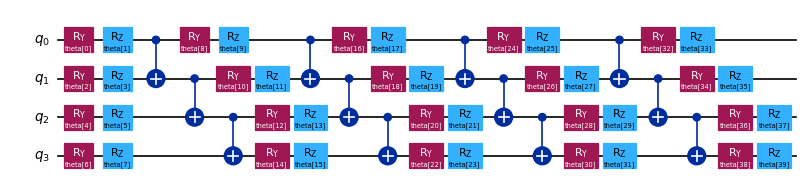

In [6]:
transpiler = QiskitTranspiler()
executable = transpiler.transpile(
    vqe_energy,
    bindings={"n": n_qubits, "H": hamiltonian},
    parameters=["theta"],
)

qk_circuit = executable.quantum_circuit
print("Qiskit parameters:", len(qk_circuit.parameters), "| depth:", qk_circuit.depth(),
      "| ops:", dict(qk_circuit.count_ops()))
qk_circuit.draw("mpl", fold=-1, scale=0.6)

## 7) Run VQE

The energy is evaluated exactly (statevector estimator) through Qamomile's Qiskit executor and minimized with SciPy's BFGS from a random start.

In [7]:
executor = QiskitExecutor()  # local simulator / statevector estimator

def energy(theta: np.ndarray) -> float:
    return float(executable.run(executor, bindings={"theta": np.asarray(theta)}).result())

rng = np.random.default_rng(42)
initial_params = rng.uniform(0, np.pi, n_params)

cost_history = [energy(initial_params)]
def callback(theta):
    cost_history.append(energy(theta))

result = minimize(
    energy,
    initial_params,
    method="BFGS",
    options={"disp": True, "maxiter": 300, "gtol": 1e-5},
    callback=callback,
)
print(result.message)

Optimization terminated successfully.
         Current function value: -1.105933
         Iterations: 161
         Function evaluations: 6765
         Gradient evaluations: 165
Optimization terminated successfully.


## 8) Results

VQE energy  : -1.10593332 Ha
FCI energy  : -1.10593335 Ha
Error       : 3.57e-08 Ha  (0.0000 kcal/mol)


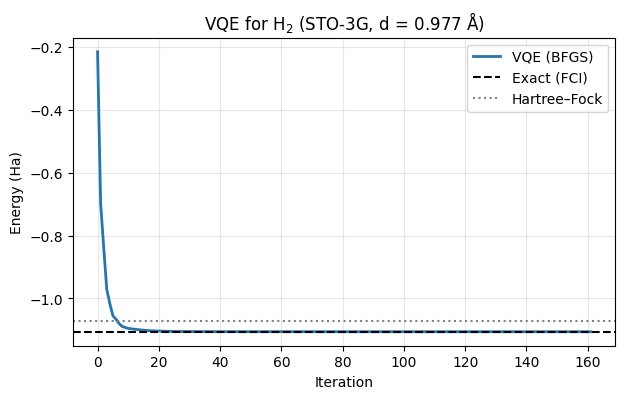

In [8]:
vqe_energy_ha = result.fun
error = vqe_energy_ha - molecule.fci_energy

print(f"VQE energy  : {vqe_energy_ha:.8f} Ha")
print(f"FCI energy  : {molecule.fci_energy:.8f} Ha")
print(f"Error       : {error:.2e} Ha  ({error * 627.5095:.4f} kcal/mol)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cost_history, lw=2, label="VQE (BFGS)")
ax.axhline(molecule.fci_energy, ls="--", color="black", label="Exact (FCI)")
ax.axhline(molecule.hf_energy, ls=":", color="gray", label="Hartree–Fock")
ax.set_xlabel("Iteration")
ax.set_ylabel("Energy (Ha)")
ax.set_title(f"VQE for H$_2$ (STO-3G, d = {distance} Å)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()